# FT-Transformer: employee resignation prediction
1.
This notebook displays results from the completed FT-Transformer
experiment. The results were checked against the original predictions.

Running the notebook checks and displays these saved results.
It does not train the model again.

Individual employee predictions are not included. The graphs use
summarized data, while AP and ROC-AUC come from the original predictions.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import yaml
from IPython.display import display, Markdown
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/feature_contract.yaml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluation.inputs import load_development_data
from src.evaluation.oof_validation import validate_oof_predictions
from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.calibration import reliability_table
from src.models.config import load_model_config
from src.models.ft_transformer_execution import run, load_formal_ft_input
from src.models.experiment_outputs import create_run_directory

RUN_TRAINING = False
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOUR = "#7651a8"
FIGURES = []
def show_figure(fig, caption):
    fig.tight_layout()
    FIGURES.append(fig)
    plt.show()
    display(Markdown(caption))

config = load_model_config(ROOT / "configs/models/ft_transformer.yaml", strict_schema=True)
contract = yaml.safe_load((ROOT / "configs/feature_contract.yaml").read_text(encoding="utf-8"))
print("Mode:", "explicit isolated training" if RUN_TRAINING else "saved review")

Mode: saved review


## Development data and quality

The shared loader verifies the frozen dataset and split hashes. It reads identifiers first,
then excludes holdout rows **before parsing their predictors or labels**. Shape logs describe
this isolation. We check uniqueness, missing values, binary labels and approved features;
no additional filtering or resampling is performed during review.

In [2]:
development_data, split_registry = load_development_data(ROOT)
features = contract["primary_model_features"]
numerical = [item["name"] for item in contract["numerical_features"]]
categorical = [item["name"] for item in contract["categorical_features"]]
assert development_data.shape == (80_000, 20)
assert development_data.Employee_ID.is_unique
assert set(development_data.Resigned.unique()) == {0, 1}
assert set(features) == set(numerical + categorical)
assert not set(features) & {"Employee_ID", "Hire_Date", "Resigned"}
assert development_data[features].isna().sum().sum() == 0
display(pd.DataFrame({"Check": ["Development rows", "Approved predictors", "Duplicate IDs",
                               "Missing predictor values"],
                      "Value": [len(development_data), len(features),
                                development_data.Employee_ID.duplicated().sum(),
                                development_data[features].isna().sum().sum()]}))

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,Check,Value
0,Development rows,80000
1,Approved predictors,17
2,Duplicate IDs,0
3,Missing predictor values,0


## Class imbalance and frozen folds

Most employees stayed, so high accuracy can be achieved by predicting only that class.
We therefore prioritize AP and compare it with resignation prevalence. Five frozen folds
provide 16,000 validation rows each; their union is the development set. Candidate weighting
is computed only from the relevant training labels, never from validation or holdout labels.

,rows,resigned,prevalence
cv_fold,,,
1.0,16000,1601,0.100062
2.0,16000,1601,0.100062
3.0,16000,1602,0.100125
4.0,16000,1602,0.100125
5.0,16000,1602,0.100125


Prevalence: 10.01%; majority-only accuracy: 89.99%


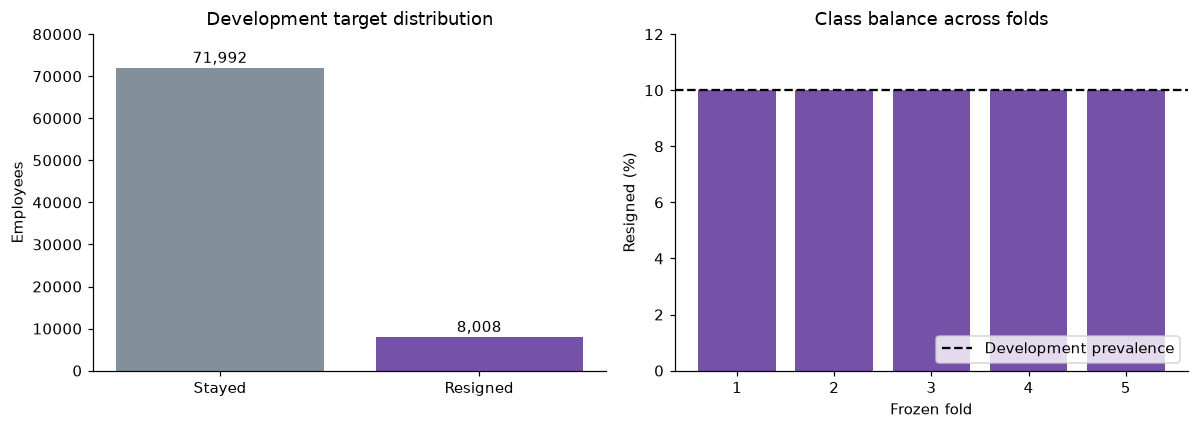

**Figure 1.** Resignations are the minority class; the frozen folds have similar class proportions.

In [3]:
dev_registry = split_registry.loc[split_registry.partition == "development"]
holdout_ids = set(split_registry.loc[split_registry.partition == "holdout", "Employee_ID"])
assert len(dev_registry) == 80_000 and len(holdout_ids) == 20_000
assert set(development_data.Employee_ID) == set(dev_registry.Employee_ID)
assert set(development_data.Employee_ID).isdisjoint(holdout_ids)
assert set(dev_registry.cv_fold) == {1, 2, 3, 4, 5}
assert dev_registry.cv_fold.value_counts().eq(16_000).all()
fold_data = development_data.merge(dev_registry[["Employee_ID", "cv_fold"]],
                                   on="Employee_ID", validate="one_to_one")
fold_balance = fold_data.groupby("cv_fold").Resigned.agg(rows="size", resigned="sum", prevalence="mean")
prevalence = float(development_data.Resigned.mean())
constant_brier = prevalence * (1 - prevalence)
display(fold_balance)
print(f"Prevalence: {prevalence:.2%}; majority-only accuracy: {1-prevalence:.2%}")
counts = development_data.Resigned.value_counts().reindex([0, 1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Stayed", "Resigned"], counts, color=["#82909a", COLOUR])
for i, count in enumerate(counts):
    axes[0].text(i, count + 1200, f"{count:,}", ha="center")
axes[0].set(ylim=(0, 80_000), ylabel="Employees", title="Development target distribution")
axes[1].bar(fold_balance.index, fold_balance.prevalence * 100, color=COLOUR)
axes[1].axhline(prevalence * 100, color="black", linestyle="--", label="Development prevalence")
axes[1].set(xlabel="Frozen fold", ylabel="Resigned (%)", ylim=(0, 12), xticks=range(1, 6),
            title="Class balance across folds")
axes[1].legend(loc="lower right")
show_figure(fig, "**Figure 1.** Resignations are the minority class; the frozen folds have similar class proportions.")

## Features and training-only preprocessing

Each fit standardizes numerical predictors using its own training statistics and learns
categorical vocabularies from its training rows. The adapter reserves representations for
missing/unknown categorical values. Validation data is transformed without refitting.

The formal pipeline uses the original 17 predictors rather than Principal Component Analysis
(PCA): feature tokens retain the numerical and categorical inputs directly. This is the tested
representation, not a claim that PCA could never help.

In [4]:
assert len(numerical) == 13 and len(categorical) == 4 and len(features) == 17
display(pd.DataFrame([{"Feature": name, "Type": kind, "Transformation": transformation}
                      for names, kind, transformation in
                      [(numerical, "Numerical", "Training-only standardization"),
                       (categorical, "Categorical", "Training-only vocabulary and embedding")]
                      for name in names]))

,Feature,Type,Transformation
0,Age,Numerical,Training-only standardization
1,Years_At_Company,Numerical,Training-only standardization
2,Performance_Score,Numerical,Training-only standardization
3,Monthly_Salary,Numerical,Training-only standardization
4,Work_Hours_Per_Week,Numerical,Training-only standardization
5,Projects_Handled,Numerical,Training-only standardization
6,Overtime_Hours,Numerical,Training-only standardization
7,Sick_Days,Numerical,Training-only standardization
8,Remote_Work_Frequency,Numerical,Training-only standardization
9,Team_Size,Numerical,Training-only standardization


## How FT-Transformer processes an employee

A **token** is a learned vector representing a feature. Numerical tokenizers and categorical
embeddings create those vectors. Multi-head self-attention combines information across features,
followed by a feed-forward network (FFN). A binary output head produces a logit, converted by
sigmoid into a score between zero and one. Attention is not a causal explanation, and a score
is not automatically a calibrated real-world probability.

## Historical context and formal candidates

The three earlier experiments below used different protocols. Their measured summaries provide
**descriptive historical context**, not a controlled comparison with the current nested run.
The [historical companion](05_m1_ft_transformer_historical.ipynb) preserves all 15 executable
historical code cells and their explanations. Weighting changed threshold behaviour without
establishing useful ranking.

FT01–FT08 are the formal YAML candidate registry. They vary architecture, learning rate and
unweighted versus training-local negative/positive-ratio weighting. All use binary cross-entropy,
AdamW, dropout and inner AP early stopping (100-epoch cap, patience 15).

In [6]:
base = ROOT / "results/models/ft_transformer"
historical_sources = [
    ("Unweighted fixed", "unweighted_baseline/ft_transformer_summary_metrics.json"),
    ("Weighted fixed", "weighted_fixed_baseline/ft_transformer_weighted_summary_metrics.json"),
    ("Weighted early stopping", "weighted_early_stopping_final/ft_transformer_final_summary_metrics.json")]
history = []
for label, relative in historical_sources:
    saved = json.loads((base / relative).read_text(encoding="utf-8"))
    history.append({"Historical experiment": label, "AP": saved["pooled_average_precision"],
                    "ROC-AUC": saved["pooled_roc_auc"], "Brier": saved["pooled_brier_score"]})
display(pd.DataFrame(history))
candidate_table = pd.DataFrame([dict(candidate_id=c["id"], **c["params"]) for c in config["candidates"]])
candidate_ids = candidate_table.candidate_id.tolist()
assert candidate_ids == [f"FT{i:02}" for i in range(1, 9)]
varying = [col for col in candidate_table if candidate_table[col].nunique() > 1]
display(candidate_table[varying])
print("Common settings:", {col: candidate_table[col].iloc[0]
                           for col in candidate_table if col not in varying})

,Historical experiment,AP,ROC-AUC,Brier
0,Unweighted fixed,0.101132,0.498821,0.090651
1,Weighted fixed,0.098820,0.495721,0.251497
2,Weighted early stopping,0.099979,0.497254,0.247413


,candidate_id,n_blocks,d_block,attention_n_heads,ffn_d_hidden,learning_rate,weighting
0,FT01,3,64,4,128,0.0010,none
1,FT02,3,64,4,128,0.0010,dynamic_ratio
2,FT03,2,64,4,128,0.0010,none
3,FT04,2,64,4,128,0.0010,dynamic_ratio
4,FT05,3,64,4,128,0.0001,none
5,FT06,3,64,4,128,0.0001,dynamic_ratio
6,FT07,3,128,8,256,0.0010,none
7,FT08,3,128,8,256,0.0010,dynamic_ratio


Common settings: {'ffn_dropout': np.float64(0.1)}


## Formal nested evaluation: select inside, evaluate outside

Each outer round reserves 16,000 employees for prediction only. Its 64,000 training rows are
split into 54,400 inner-training and 9,600 inner-validation rows. The inner split selects a
candidate and epoch count; a **fresh model with fresh preprocessing** then fits all 64,000
outer-training rows. Five rounds produce 40 candidate evaluations and five winner refits.

Default review loads checksum/provenance-validated canonical evidence, with no historical
fallback. Setting `RUN_TRAINING=True` in setup deliberately creates a new rerun directory;
subsequent analysis uses that returned run rather than the canonical results.

In [7]:
if RUN_TRAINING:
    active_results_dir = create_run_directory(ROOT, "ft_transformer")
    oof, fold_metrics, summary = run(ROOT, output_dir=active_results_dir)
else:
    active_results_dir = ROOT / "results/models/ft_transformer/strict_nested"
    oof, fold_metrics, summary = load_formal_ft_input(ROOT)
validate_oof_predictions(oof, split_registry, source_data=development_data,
                         expected_model_name="FT-Transformer")
selection = pd.read_csv(active_results_dir / "candidate_selection.csv")
selection_evidence = json.loads((active_results_dir / "selection_evidence.json").read_text(encoding="utf-8"))
assert len(selection) == 40 and len(selection_evidence) == 5
assert not selection.duplicated(["outer_fold", "candidate_id"]).any()
assert set(selection.candidate_id) == set(candidate_ids)
assert selection.groupby("outer_fold").size().eq(8).all()
assert np.isfinite(selection.inner_ap).all() and selection.inner_ap.between(0, 1).all()
assert selection.selected_epoch_count.between(1, 100).all()
assert (selection.selected_epoch_count % 1 == 0).all()
print("Active evidence:", active_results_dir.relative_to(ROOT))

Active evidence: results\models\ft_transformer\strict_nested


## Candidate-selection evidence

Inner AP scores support selection **within each fold**. They are not unbiased outer performance
estimates for fixed candidates. The markers identify the actual recorded winners; the second
panel shows the epoch counts used for their fresh outer-training refits. No epoch-by-epoch loss
curves are available in the saved formal evidence.

,fold,selected_candidate,selected_epoch_count
0,1,FT02,16
1,2,FT05,1
2,3,FT02,17
3,4,FT03,36
4,5,FT01,30


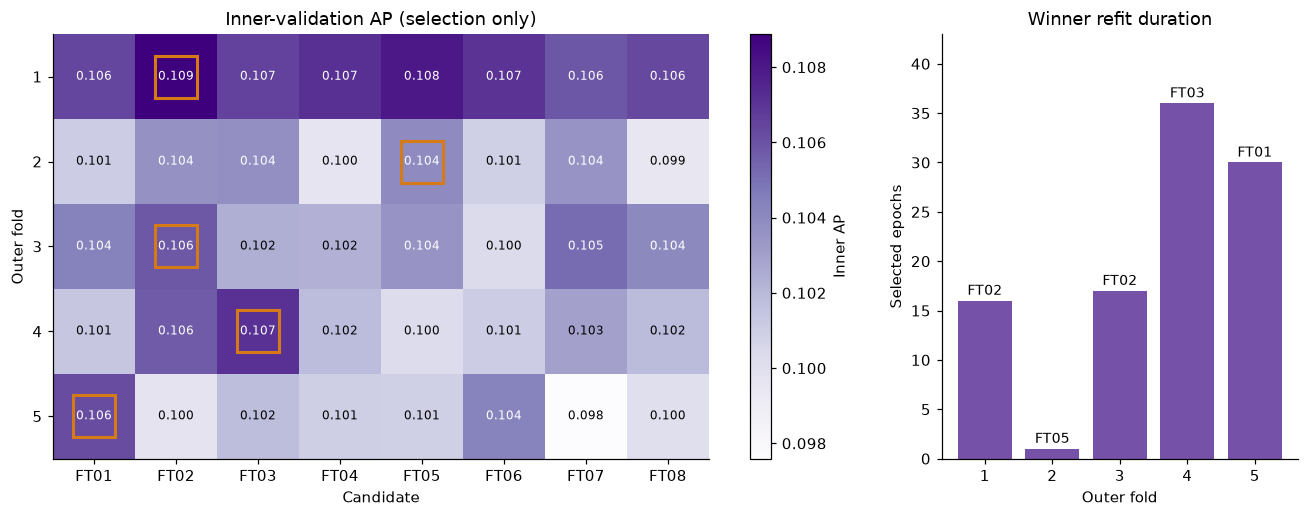

**Figure 3.** Orange outlines mark recorded winners. Candidate scores and selected durations vary across inner splits.

In [8]:
winners = fold_metrics.sort_values("fold")[["fold", "selected_candidate", "selected_epoch_count"]]
display(winners)
inner_ap = selection.pivot(index="outer_fold", columns="candidate_id", values="inner_ap").reindex(
    index=range(1, 6), columns=candidate_ids)
assert inner_ap.notna().all().all()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2.3, 1]})
im = axes[0].imshow(inner_ap, cmap="Purples", aspect="auto")
axes[0].set(xticks=range(8), xticklabels=candidate_ids, yticks=range(5), yticklabels=range(1, 6),
            xlabel="Candidate", ylabel="Outer fold", title="Inner-validation AP (selection only)")
for i in range(5):
    for j in range(8):
        axes[0].text(j, i, f"{inner_ap.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8,
                     color="white" if inner_ap.iloc[i, j] > (inner_ap.min().min()+inner_ap.max().max())/2 else "black")
for row in winners.itertuples(index=False):
    axes[0].plot(candidate_ids.index(row.selected_candidate), row.fold-1, marker="s",
                 markersize=27, markerfacecolor="none", markeredgecolor="#d57a16", markeredgewidth=2)
fig.colorbar(im, ax=axes[0], label="Inner AP")
axes[1].bar(winners.fold, winners.selected_epoch_count, color=COLOUR)
for row in winners.itertuples(index=False):
    axes[1].text(row.fold, row.selected_epoch_count+0.6, row.selected_candidate,
                 ha="center", fontsize=9)
axes[1].set(xlabel="Outer fold", ylabel="Selected epochs", xticks=range(1, 6),
            ylim=(0, winners.selected_epoch_count.max()+7), title="Winner refit duration")
show_figure(fig, "**Figure 3.** Orange outlines mark recorded winners. Candidate scores and selected durations vary across inner splits.")

## Outer-fold performance

These scores evaluate the entire nested selection procedure on untouched outer-validation rows.
Mean and sample standard deviation (SD) describe fold variability; SD is neither a confidence
interval nor a significance test. The zoomed axes make small differences visible without
establishing practical superiority.

,fold,selected_candidate,selected_epoch_count,average_precision,roc_auc,brier_score,precision,recall,f1,balanced_accuracy,accuracy,predicted_positive_rate,tn,fp,fn,tp
0,1,FT02,16,0.096581,0.493389,0.242686,0.083598,0.049344,0.062058,0.494601,0.850750,0.059062,13533,866,1522,79
1,2,FT05,1,0.101352,0.505661,0.090118,Unavailable,0.000000,0.000000,0.500000,0.899937,0.000000,14399,0,1601,0
2,3,FT02,17,0.095313,0.484555,0.252314,0.095386,0.480025,0.159147,0.486748,0.492125,0.503875,7105,7293,833,769
3,4,FT03,36,0.100386,0.495808,0.090162,Unavailable,0.000000,0.000000,0.500000,0.899875,0.000000,14398,0,1602,0
4,5,FT01,30,0.096695,0.490546,0.090150,Unavailable,0.000000,0.000000,0.500000,0.899875,0.000000,14398,0,1602,0


,mean,sample SD
average_precision,0.098065,0.002638
roc_auc,0.493992,0.007758
brier_score,0.153086,0.086255


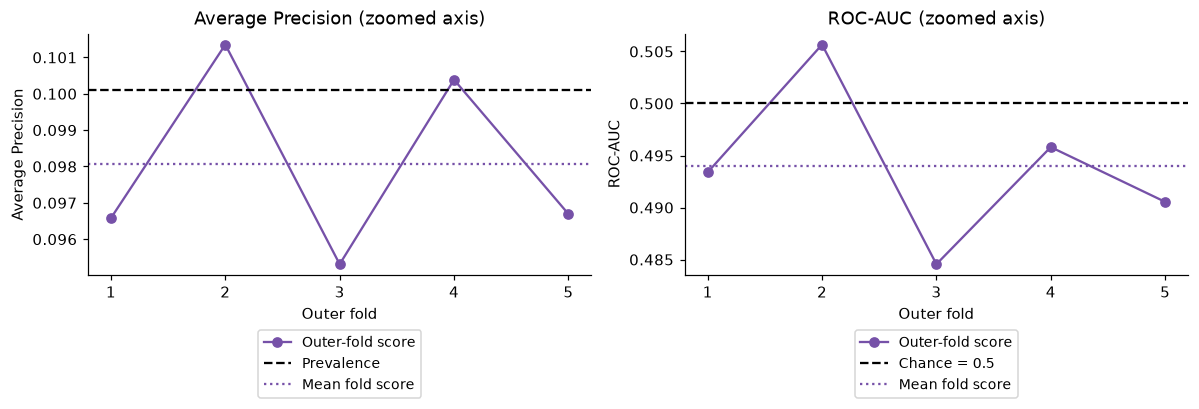

**Figure 4.** Fold scores fluctuate around the reference levels; these fluctuations are descriptive evidence, not proof of useful discrimination.

In [9]:
metrics_to_check = ["average_precision", "roc_auc", "brier_score", "precision", "recall", "f1",
                    "balanced_accuracy", "accuracy", "predicted_positive_rate", "tn", "fp", "fn", "tp"]
fold_display = fold_metrics[["fold", "selected_candidate", "selected_epoch_count", *metrics_to_check]].copy()
fold_display.loc[fold_display.tp + fold_display.fp == 0, "precision"] = np.nan
display(fold_display.fillna("Unavailable"))
fold_summary = fold_metrics[["average_precision", "roc_auc", "brier_score"]].agg(["mean", "std"]).T
display(fold_summary.rename(columns={"std": "sample SD"}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, reference, title in zip(axes, ["average_precision", "roc_auc"],
                                      [prevalence, 0.5], ["Average Precision", "ROC-AUC"]):
    values = fold_metrics[metric]
    ax.plot(fold_metrics.fold, values, "o-", color=COLOUR, label="Outer-fold score")
    ax.axhline(reference, color="black", linestyle="--", label="Prevalence" if metric == "average_precision" else "Chance = 0.5")
    ax.axhline(values.mean(), color=COLOUR, linestyle=":", label="Mean fold score")
    ax.set(xlabel="Outer fold", ylabel=title, xticks=range(1, 6), title=f"{title} (zoomed axis)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)
show_figure(fig, "**Figure 4.** Fold scores fluctuate around the reference levels; these fluctuations are descriptive evidence, not proof of useful discrimination.")

## Overall discrimination: pooled out-of-fold predictions

**Out-of-fold (OOF)** means each employee was predicted without being used to train that model.
Pooled AP is calculated once across all 80,000 OOF scores; mean fold AP averages five separate
calculations. They need not agree. Pooling also compares scores from independently fitted
models whose score scales may differ, so pooled curves do not represent one frozen deployment model.

,Measure,Value
0,Pooled AP,0.098648
1,Mean fold AP,0.098065
2,No-skill AP reference,0.100100
3,Pooled ROC-AUC,0.497980


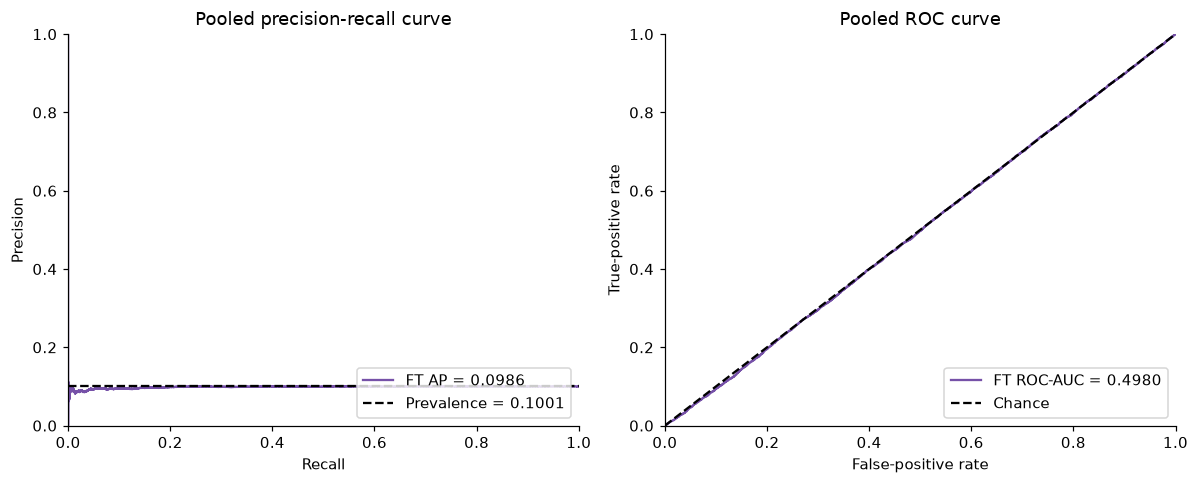

**Figure 5.** AP near prevalence and ROC-AUC near 0.5 indicate near-chance discrimination.

In [10]:
pooled = calculate_binary_metrics(oof.y_true, oof.y_probability)
display(pd.DataFrame({"Measure": ["Pooled AP", "Mean fold AP", "No-skill AP reference", "Pooled ROC-AUC"],
                      "Value": [pooled["average_precision"], fold_metrics.average_precision.mean(),
                                prevalence, pooled["roc_auc"]]}))
precision, recall, _ = precision_recall_curve(oof.y_true, oof.y_probability)
fpr, tpr, _ = roc_curve(oof.y_true, oof.y_probability)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(recall, precision, color=COLOUR, label=f"FT AP = {pooled['average_precision']:.4f}")
axes[0].axhline(prevalence, color="black", linestyle="--", label=f"Prevalence = {prevalence:.4f}")
axes[0].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1), title="Pooled precision-recall curve")
axes[1].plot(fpr, tpr, color=COLOUR, label=f"FT ROC-AUC = {pooled['roc_auc']:.4f}")
axes[1].plot([0, 1], [0, 1], "--", color="black", label="Chance")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", xlim=(0, 1), ylim=(0, 1), title="Pooled ROC curve")
for ax in axes:
    ax.legend(loc="lower right")
show_figure(fig, "**Figure 5.** AP near prevalence and ROC-AUC near 0.5 indicate near-chance discrimination.")

## Probability quality and a fixed threshold

Brier score measures mean squared probability error (lower is better). Predicting prevalence for
everyone gives reference error `p(1-p)`. Reliability compares scores with observed event rates in
ten equal-width bins; empty bins provide no measurements. Histograms normalize each true class
separately so the minority distribution remains visible.

Threshold 0.50 is descriptive, not an adopted retention policy. Precision is unavailable when
no employees are predicted positive. These OOF labels are not used to fit a calibrator or choose
an operational threshold; weighting may distort raw score calibration.

,Diagnostic,Value
0,Brier,0.153086
1,Constant-prevalence Brier,0.090080
2,Precision @ 0.50,0.094149
3,Recall @ 0.50,0.105894
4,F1 @ 0.50,0.099677
5,Balanced accuracy @ 0.50,0.496281
6,Predicted-positive rate,0.112587


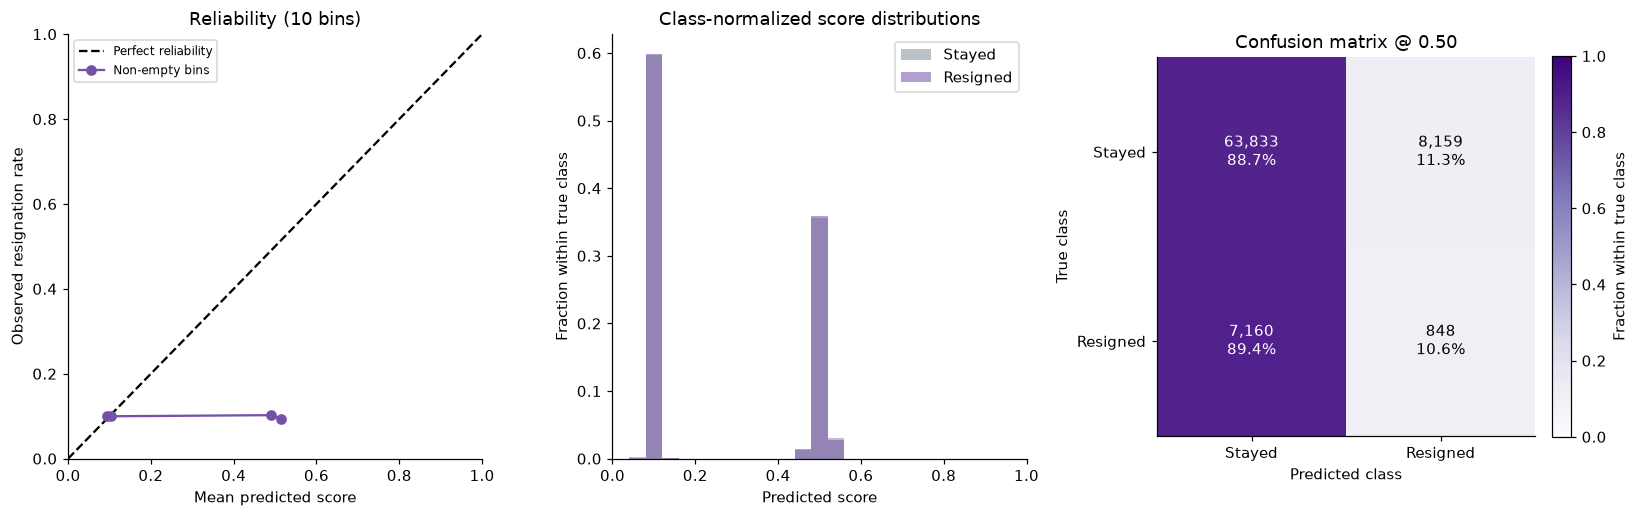

**Figure 6.** Overlapping class scores indicate weak separation. Probability error and threshold behaviour are separate from ranking quality.

In [11]:
predicted = (oof.y_probability.to_numpy() >= 0.5).astype(int)
cm = confusion_matrix(oof.y_true, predicted, labels=[0, 1])
normalized_cm = np.divide(cm, cm.sum(axis=1, keepdims=True),
                          out=np.full(cm.shape, np.nan), where=cm.sum(axis=1, keepdims=True) != 0)
reliability = reliability_table(oof.y_true, oof.y_probability, n_bins=10)
observed = reliability.loc[reliability["count"] > 0]
diagnostics = {"Brier": pooled["brier_score"], "Constant-prevalence Brier": constant_brier,
               "Precision @ 0.50": pooled["precision"] if predicted.sum() else np.nan,
               "Recall @ 0.50": pooled["recall"] if oof.y_true.sum() else np.nan,
               "F1 @ 0.50": pooled["f1"] if predicted.sum()+oof.y_true.sum() else np.nan,
               "Balanced accuracy @ 0.50": pooled["balanced_accuracy"],
               "Predicted-positive rate": predicted.mean()}
display(pd.DataFrame(diagnostics.items(), columns=["Diagnostic", "Value"]).fillna("Unavailable"))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
axes[0].plot([0, 1], [0, 1], "--", color="black", label="Perfect reliability")
axes[0].plot(observed.mean_probability, observed.observed_rate, "o-", color=COLOUR, label="Non-empty bins")
axes[0].set(xlabel="Mean predicted score", ylabel="Observed resignation rate", xlim=(0, 1), ylim=(0, 1), title="Reliability (10 bins)")
axes[0].legend(fontsize=8)
for cls, label, colour in [(0, "Stayed", "#82909a"), (1, "Resigned", COLOUR)]:
    values = oof.loc[oof.y_true == cls, "y_probability"]
    axes[1].hist(values, bins=np.linspace(0, 1, 26), weights=np.ones(len(values))/len(values),
                 alpha=0.55, label=label, color=colour)
axes[1].set(xlabel="Predicted score", ylabel="Fraction within true class", xlim=(0, 1), title="Class-normalized score distributions")
axes[1].legend()
im = axes[2].imshow(normalized_cm, vmin=0, vmax=1, cmap="Purples")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i,j]:,}\n{normalized_cm[i,j]:.1%}", ha="center", va="center",
                     color="white" if normalized_cm[i,j] > 0.5 else "black")
axes[2].set(xticks=[0, 1], xticklabels=["Stayed", "Resigned"], yticks=[0, 1], yticklabels=["Stayed", "Resigned"],
            xlabel="Predicted class", ylabel="True class", title="Confusion matrix @ 0.50")
fig.colorbar(im, ax=axes[2], label="Fraction within true class", fraction=0.046, pad=0.04)
show_figure(fig, "**Figure 6.** Overlapping class scores indicate weak separation. Probability error and threshold behaviour are separate from ranking quality.")

## Final verification and interpretation

Verify saved pooled/fold metrics against recomputation, reconcile candidate records with winner
evidence, and confirm development-only predictions. The group ranks by **pooled AP** and reports
mean fold AP separately. A small numerical score difference is not evidence of practical usefulness.
No deployment model is frozen and the holdout remains locked. Saved review verifies evidence;
it does not independently repeat the expensive training experiment.

In [12]:
validate_oof_predictions(oof, split_registry, source_data=development_data,
                         expected_model_name="FT-Transformer")
assert len(fold_metrics) == 5 and set(fold_metrics.fold) == {1, 2, 3, 4, 5}
assert len(FIGURES) == 6
for metric in metrics_to_check:
    assert np.isclose(pooled[metric], summary[metric], rtol=1e-9, atol=1e-12), metric
assert np.isclose(summary["cv_mean_ap"], fold_metrics.average_precision.mean())
assert np.isclose(summary["cv_std_ap"], fold_metrics.average_precision.std(ddof=1))
assert summary["development_rows"] == 80_000 and summary["candidate_evaluations"] == 40
assert not summary["formal_holdout_used"] and not summary["final_model_frozen"]
for row in fold_metrics.itertuples(index=False):
    frame = oof.loc[oof.cv_fold == row.fold]
    actual = calculate_binary_metrics(frame.y_true, frame.y_probability)
    for metric in metrics_to_check:
        assert np.isclose(actual[metric], getattr(row, metric), rtol=1e-9, atol=1e-12), (row.fold, metric)
    evidence = next(item for item in selection_evidence if item["outer_fold"] == row.fold)
    assert evidence["fitted_on_all_outer_rows"]
    assert evidence["winning_candidate_id"] == row.selected_candidate
    assert evidence["selected_epoch_count"] == row.selected_epoch_count
    selected = selection.loc[(selection.outer_fold == row.fold) &
                              (selection.candidate_id == row.selected_candidate)].iloc[0]
    assert selected.selected_epoch_count == row.selected_epoch_count
    assert np.isclose(selected.inner_ap, selection.loc[selection.outer_fold == row.fold, "inner_ap"].max())
    for cid, candidate in evidence["all_candidates"].items():
        recorded = selection.loc[(selection.outer_fold == row.fold) & (selection.candidate_id == cid)].iloc[0]
        assert np.isclose(recorded.inner_ap, candidate["inner_ap"])
        assert recorded.selected_epoch_count == candidate["selected_epoch_count"]
display(pd.DataFrame({"Formal measure": ["Pooled AP", "Mean fold AP", "Pooled ROC-AUC", "Brier"],
                      "Value": [pooled["average_precision"], summary["cv_mean_ap"], pooled["roc_auc"], pooled["brier_score"]]}))
if RUN_TRAINING:
    interpretation = "This is an isolated new run; it does not replace the group's canonical input. Assess its scores against the baselines above."
else:
    interpretation = "The canonical FT-Transformer result shows near-chance discrimination under the tested protocol; it does not demonstrate useful resignation prediction."
display(Markdown(f"**Conclusion.** {interpretation} Pooled AP is **{pooled['average_precision']:.6f}** "
                 f"versus prevalence **{prevalence:.6f}**; ROC-AUC is **{pooled['roc_auc']:.6f}**. "
                 "One inner split adds selection variance, the candidate search is bounded, and predictive associations are not causal explanations. "
                 "**No deployment model is frozen; the formal holdout remains locked.** "
                 "The group continues to use `results/models/ft_transformer/strict_nested/oof_predictions.csv`."))
print("Integrity checks passed: 80,000 development predictions, five folds, six figure groups.")

,Formal measure,Value
0,Pooled AP,0.098648
1,Mean fold AP,0.098065
2,Pooled ROC-AUC,0.497980
3,Brier,0.153086


**Conclusion.** The canonical FT-Transformer result shows near-chance discrimination under the tested protocol; it does not demonstrate useful resignation prediction. Pooled AP is **0.098648** versus prevalence **0.100100**; ROC-AUC is **0.497980**. One inner split adds selection variance, the candidate search is bounded, and predictive associations are not causal explanations. **No deployment model is frozen; the formal holdout remains locked.** The group continues to use `results/models/ft_transformer/strict_nested/oof_predictions.csv`.

Integrity checks passed: 80,000 development predictions, five folds, six figure groups.
